# Olist 리뷰 데이터 전처리 & 텍스트 마이닝 (경로 B: 포르투갈어 → 영어 번역)

## 개요
- Olist `olist_order_reviews_dataset.csv`의 `review_comment_message`(포르투갈어)를 `deep-translator`로 영어 번역
- 번역 후에는 기존 **영어 실습 코드 구조를 그대로** 사용 (영어 stopwords, bigrams/trigrams, 평점별 비교, 워드클라우드, VADER)

## ⚠️ 번역 시간 & 전략
- 본문 있는 리뷰 약 **40,977건** → 전량 번역 시 **30분~1.5시간** 소요 가능
- `SAMPLE_SIZE` 변수로 먼저 작게(예: 3,000건) 테스트 후 전체 진행 권장
- 번역 결과는 `reviews_pt_to_en.csv`에 **캐시**되어, 커널이 죽어도 재개 가능

---
## 1. 데이터 로드 & 기본 탐색

In [1]:
import pandas as pd

df = pd.read_csv('olist_order_reviews_dataset.csv')
df

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53
...,...,...,...,...,...,...,...
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07 00:00:00,2018-07-14 17:18:30
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09 00:00:00,2017-12-11 20:06:42
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super...",2018-03-22 00:00:00,2018-03-23 09:10:43
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01 00:00:00,2018-07-02 12:59:13


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB


In [3]:
df.describe()

,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [4]:
# 결측치 확인
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)

miss_df = pd.DataFrame(
    {
        'count': missing,
        'percentage': missing_pct
    }
)
miss_df

,count,percentage
review_id,0,0.00
order_id,0,0.00
review_score,0,0.00
review_comment_title,87656,88.34
review_comment_message,58247,58.70
review_creation_date,0,0.00
review_answer_timestamp,0,0.00


> 💡 `review_comment_title`은 ~88%, `review_comment_message`는 ~59% 결측 → 본문이 있는 행만 텍스트 마이닝에 사용합니다.

---
## 2. 평점(review_score) 분포 분석

In [5]:
# 평점 분포 (개수 & 퍼센트)
rating_dist = df['review_score'].value_counts().sort_index()

rating_dist_df = pd.DataFrame(
    {
        'Rating': rating_dist.index,
        'Count': rating_dist.values,
        'Percentage': (rating_dist.values / len(df) * 100).round(2)
    }
)
rating_dist_df

,Rating,Count,Percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


In [ ]:
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

# Mac에서 한국어 깨짐 방지
matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus'] = False

# 고유값 30개 이하 컬럼에 대해서만 분포 시각화
for i in df.columns:
    if df[i].nunique() > 30:
        continue

    dist = df[i].value_counts().sort_index()
    dist = pd.DataFrame(
        {
            i.capitalize(): dist.index,
            'Count': dist.values,
            'Percentage': (dist.values / len(df) * 100).round(2),
        }
    )

    plt.figure(figsize=(10, 5))
    ax = sns.barplot(
        data=dist,
        x=i.capitalize(),
        y='Percentage',
        hue=i.capitalize(),
        palette='viridis',
        legend=False,
    )

    for p in ax.patches:
        ax.annotate(
            f'{p.get_height():.1f}%',
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center', va='center',
            xytext=(0, 9),
            textcoords='offset points',
        )

    plt.title(f'Distribution of {i.capitalize()}', fontsize=15)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

---
## 3. 텍스트 마이닝 준비 — 본문 있는 리뷰만 추출

In [7]:
# 리뷰 본문이 있는 행만 남기고, 영어 실습 코드와 컬럼명 맞추기
reviews = df[df['review_comment_message'].notna()].copy()
reviews = reviews.rename(columns={
    'review_comment_message': 'Review Text PT',   # 포르투갈어 원문
    'review_score': 'Rating'
})

print(f'분석 대상 리뷰 수: {len(reviews):,}')
reviews[['Rating', 'Review Text PT']].head()

분석 대상 리뷰 수: 40,977


,Rating,Review Text PT
3,5,Recebi bem antes do prazo estipulado.
4,5,Parabéns lojas lannister adorei comprar pela I...
9,4,aparelho eficiente. no site a marca do aparelh...
12,4,"Mas um pouco ,travando...pelo valor ta Boa.\r\n"
15,5,"Vendedor confiável, produto ok e entrega antes..."


---
## 4. 포르투갈어 → 영어 번역 (deep-translator)

- `SAMPLE_SIZE`로 번역 건수 조절 (테스트 시 작게)
- 배치 단위로 `translate_batch` 호출 → 건당 호출보다 훨씬 빠름
- 번역된 건은 `reviews_pt_to_en.csv`에 캐시 → 재실행 시 이어서 진행

In [8]:
# 패키지 설치 (한 번만 실행)
import sys
!{sys.executable} -m pip install deep-translator tqdm nltk vaderSentiment wordcloud scikit-learn
!pip install deep-translator tqdm nltk vaderSentiment wordcloud scikit-learn


[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
zsh:1: command not found: pip


In [9]:
# ⚙️ 번역 설정
SAMPLE_SIZE = 3000        # None이면 전체, 숫자면 랜덤 샘플링 (테스트용으로 3000 권장)
BATCH_SIZE = 50           # 한 번에 번역할 건수
CHECKPOINT_EVERY = 10     # 몇 배치마다 캐시 저장할지 (10 배치 = 500건)
CACHE_FILE = 'reviews_pt_to_en.csv'

# 대상 리뷰 결정
if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(reviews):
    target = reviews.sample(n=SAMPLE_SIZE, random_state=42).copy()
    print(f'🧪 샘플링: {len(target):,}건 번역 예정')
else:
    target = reviews.copy()
    print(f'📦 전체 번역: {len(target):,}건')

🧪 샘플링: 3,000건 번역 예정


In [ ]:
import os
from deep_translator import GoogleTranslator
from tqdm.auto import tqdm

translator = GoogleTranslator(source='pt', target='en')

# --- 1) 캐시 로드 ---
if os.path.exists(CACHE_FILE):
    cache_df = pd.read_csv(CACHE_FILE)
    translations = dict(zip(cache_df['review_id'], cache_df['review_en']))
    print(f'✓ 캐시에서 {len(translations):,}건 복원')
else:
    translations = {}
    print('✓ 새 캐시 시작')

# --- 2) 아직 번역 안 된 건만 추출 ---
todo = target[~target['review_id'].isin(translations)]
print(f'번역 필요: {len(todo):,}건 / 총 {len(target):,}건')

texts = todo['Review Text PT'].astype(str).tolist()
ids   = todo['review_id'].tolist()

# --- 3) 배치 번역 ---
def save_cache():
    pd.DataFrame(list(translations.items()),
                 columns=['review_id', 'review_en']).to_csv(CACHE_FILE, index=False)

num_batches = (len(texts) + BATCH_SIZE - 1) // BATCH_SIZE
for b in tqdm(range(num_batches), desc='Translating'):
    s, e = b * BATCH_SIZE, (b + 1) * BATCH_SIZE
    batch_texts = texts[s:e]
    batch_ids   = ids[s:e]

    try:
        translated = translator.translate_batch(batch_texts)
    except Exception as err:
        # 배치 실패 시 개별 호출로 폴백
        print(f'  ⚠ batch {b} failed ({err}); retrying individually')
        translated = []
        for t in batch_texts:
            try:
                translated.append(translator.translate(t) or t)
            except Exception:
                translated.append(t)  # 실패 시 원문 유지

    for rid, tr in zip(batch_ids, translated):
        translations[rid] = tr if tr else ''

    # 체크포인트 저장
    if (b + 1) % CHECKPOINT_EVERY == 0:
        save_cache()

# 최종 저장
save_cache()
print(f'\n✅ 번역 완료 — 총 캐시 {len(translations):,}건 (저장: {CACHE_FILE})')

✓ 새 캐시 시작
번역 필요: 3,000건 / 총 3,000건


Translating:   0%|          | 0/60 [00:00<?, ?it/s]

  ⚠ batch 31 failed (Produto devidamente lacrado, tudo certo. --> No translation was found using the current translator. Try another translator?); retrying individually


In [ ]:
# 번역 결과를 reviews에 붙이고, 기존 영어 실습 코드와 호환되도록 'Review Text' 컬럼 생성
reviews['Review Text'] = reviews['review_id'].map(translations)

# 번역이 수행된 행만 이후 분석에 사용
reviews_en = reviews.dropna(subset=['Review Text']).copy()
print(f'영어 번역 완료된 리뷰: {len(reviews_en):,}건')

reviews_en[['Rating', 'Review Text PT', 'Review Text']].sample(5, random_state=1)

영어 번역 완료된 리뷰: 3,045건


,Rating,Review Text PT,Review Text
170,5,"Espero receber esta semana, o que não seria tã...","I hope to receive it this week, which wouldn't..."
45912,1,Preciso entrar em contato com vcs urgente.,I need to contact you urgently.
43586,1,Fiz a compra de uma cabo para HD externo de 80...,"I purchased an 80cm external HD cable, but the..."
96697,5,O Produto tinha uma previsão de entrega para o...,The Product was scheduled for delivery on 05/2...
74304,4,Ótimo produto\r\n,Great product


---
## 5. NLTK 설정 & 영어 stopwords 로드

In [ ]:
import nltk
print('Downloading NLTK data...')
try:
    nltk.download('stopwords', quiet=True)
    nltk.download('punkt', quiet=True)
    nltk.download('averaged_perceptron_tagger', quiet=True)
    print('✓ NLTK data downloaded')
except Exception as e:
    print('⚠ NLTK download failed, will use fallback stopwords:', e)

✓ NLTK data downloaded


[nltk_data] Error loading stopwords: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1018)>
[nltk_data] Error loading punkt: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1018)>
[nltk_data] Error loading averaged_perceptron_tagger: <urlopen error
[nltk_data]     [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify
[nltk_data]     failed: unable to get local issuer certificate
[nltk_data]     (_ssl.c:1018)>


In [ ]:
import re
from collections import Counter
from nltk.corpus import stopwords
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import numpy as np

# 영어 stopwords (기존 실습 코드와 동일한 폴백 포함)
try:
    stop_words = set(stopwords.words('english'))
except Exception:
    stop_words = {'i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once'}

print(f'✓ Loaded {len(stop_words)} stopwords')

✓ Loaded 100 stopwords


In [ ]:
# 텍스트 클리닝 함수 (영어)
def clean_text(text):
    """Clean and tokenize text"""
    if pd.isna(text):
        return []
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [w for w in words if w not in stop_words and len(w) > 2]
    return words

print('\n1. Cleaning and processing review text...')
reviews_en['Review Text'] = reviews_en['Review Text'].fillna('')
reviews_en['cleaned_words'] = reviews_en['Review Text'].apply(clean_text)
print(f'✓ Processed {len(reviews_en)} reviews')
reviews_en[['Rating', 'Review Text', 'cleaned_words']].head()


1. Cleaning and processing review text...
✓ Processed 3045 reviews


,Rating,Review Text,cleaned_words
4,5,Congratulations lannister stores I loved shopp...,"[congratulations, lannister, stores, loved, sh..."
22,5,Store note 10,"[store, note]"
34,4,I received exactly what I expected. Other orde...,"[received, exactly, expected, other, orders, o..."
100,5,Satisfied,[satisfied]
127,5,"The thermal bag, besides being beautiful, is s...","[thermal, bag, besides, beautiful, super, spac..."


---
## 6. 전체 빈도 Top 30

In [ ]:
print('\n4. Top 30 Most Frequent Words:')
all_words = []
for words in reviews_en['cleaned_words']:
    all_words.extend(words)

word_freq = Counter(all_words)
top_30_words = word_freq.most_common(30)

top_words_df = pd.DataFrame(top_30_words, columns=['Word', 'Frequency'])
print(top_words_df)
top_words_df.to_csv('top_words_overall.csv', index=False)
print('✓ Saved: top_words_overall.csv')


4. Top 30 Most Frequent Words:
          Word  Frequency
0      product       1357
1         very        505
2     delivery        473
3      arrived        456
4         good        445
5    recommend        371
6     received        369
7          not        364
8    delivered        361
9         time        310
10       great        236
11   excellent        230
12     quality        222
13      bought        212
14       ahead        211
15    schedule        207
16        well        193
17         one        192
18    deadline        187
19        only        168
20       store        163
21       didnt        160
22  everything        160
23        fast        154
24        came        139
25    purchase        136
26    expected        130
27   beautiful        124
28     receive        114
29       loved        110
✓ Saved: top_words_overall.csv


---
## 7. Bigrams & Trigrams

In [ ]:
print('\n5. Extracting Bigrams and Trigrams...')

def get_ngrams(words_list, n):
    """Extract n-grams from list of word lists"""
    ngrams = []
    for words in words_list:
        if len(words) >= n:
            for i in range(len(words) - n + 1):
                ngrams.append(' '.join(words[i:i + n]))
    return ngrams

# Bigrams
bigrams = get_ngrams(reviews_en['cleaned_words'], 2)
bigram_freq = Counter(bigrams)
top_20_bigrams = bigram_freq.most_common(20)

print('\nTop 20 Bigrams:')
bigrams_df = pd.DataFrame(top_20_bigrams, columns=['Bigram', 'Frequency'])
print(bigrams_df)
bigrams_df.to_csv('top_bigrams.csv', index=False)
print('✓ Saved: top_bigrams.csv')


5. Extracting Bigrams and Trigrams...

Top 20 Bigrams:
               Bigram  Frequency
0           very good        204
1      ahead schedule        203
2     product arrived        143
3   product delivered        116
4       fast delivery        101
5    received product         96
6     quality product         79
7        good product         78
8       delivery time         70
9         product not         69
10    havent received         68
11      didnt receive         60
12   highly recommend         56
13      well packaged         55
14     delivered time         55
15      great product         54
16  excellent product         52
17    delivered ahead         52
18      arrived ahead         51
19  perfect condition         51
✓ Saved: top_bigrams.csv


In [ ]:
# Trigrams
trigrams = get_ngrams(reviews_en['cleaned_words'], 3)
trigram_freq = Counter(trigrams)
top_20_trigrams = trigram_freq.most_common(20)

print('\nTop 20 Trigrams:')
trigrams_df = pd.DataFrame(top_20_trigrams, columns=['Trigram', 'Frequency'])
print(trigrams_df)
trigrams_df.to_csv('top_trigrams.csv', index=False)
print('✓ Saved: top_trigrams.csv')


Top 20 Trigrams:
                     Trigram  Frequency
0   delivered ahead schedule         51
1     arrived ahead schedule         49
2        well ahead schedule         44
3          very good product         39
4    product delivered ahead         31
5      didnt receive product         30
6      still havent received         30
7      earlier than expected         27
8    delivery ahead schedule         26
9     product delivered time         26
10   havent received product         26
11         only received one         25
12       super fast delivery         24
13     great quality product         24
14        arrived well ahead         22
15     product arrived ahead         21
16     product not delivered         20
17      product arrived time         18
18      arrived earlier than         17
19        very well packaged         16
✓ Saved: top_trigrams.csv


---
## 8. 평점별 단어 비교 (1점 vs 5점)

In [ ]:
# 1점 리뷰 Top 15
rating_1_count = []
for words in reviews_en[reviews_en['Rating'] == 1]['cleaned_words']:
    rating_1_count.extend(words)

Counter(rating_1_count).most_common(15)

[('product', 352),
 ('not', 225),
 ('received', 173),
 ('bought', 117),
 ('delivered', 105),
 ('didnt', 96),
 ('one', 93),
 ('only', 80),
 ('receive', 77),
 ('arrived', 72),
 ('delivery', 65),
 ('havent', 59),
 ('yet', 58),
 ('still', 52),
 ('already', 52)]

In [ ]:
# 1-star vs 5-star 비교
words_1star = []
for words in reviews_en[reviews_en['Rating'] == 1]['cleaned_words']:
    words_1star.extend(words)
freq_1star = Counter(words_1star)

words_5star = []
for words in reviews_en[reviews_en['Rating'] == 5]['cleaned_words']:
    words_5star.extend(words)
freq_5star = Counter(words_5star)

print(f'\n1-Star Reviews - Top 15 words:')
print(pd.DataFrame(freq_1star.most_common(15), columns=['Word', 'Frequency']))

print(f'\n5-Star Reviews - Top 15 words:')
print(pd.DataFrame(freq_5star.most_common(15), columns=['Word', 'Frequency']))

# 합쳐서 저장
words_by_rating = pd.DataFrame({
    '1Star_Word': [w[0] for w in freq_1star.most_common(20)],
    '1Star_Freq': [w[1] for w in freq_1star.most_common(20)],
    '5Star_Word': [w[0] for w in freq_5star.most_common(20)],
    '5Star_Freq': [w[1] for w in freq_5star.most_common(20)]
})
words_by_rating.to_csv('words_by_rating.csv', index=False)
print('\n✓ Saved: words_by_rating.csv')


1-Star Reviews - Top 15 words:
         Word  Frequency
0     product        352
1         not        225
2    received        173
3      bought        117
4   delivered        105
5       didnt         96
6         one         93
7        only         80
8     receive         77
9     arrived         72
10   delivery         65
11     havent         59
12        yet         58
13      still         52
14    already         52

5-Star Reviews - Top 15 words:
         Word  Frequency
0     product        610
1        very        330
2        good        271
3    delivery        268
4   recommend        268
5     arrived        260
6   excellent        199
7       great        196
8        time        183
9       ahead        165
10   schedule        159
11  delivered        155
12       well        148
13    quality        146
14       fast        128

✓ Saved: words_by_rating.csv


---
## 9. 긍정 / 부정 리뷰 비교 (TASK 4)

In [ ]:
print('\n' + '=' * 60)
print('TASK 4: COMPARATIVE ANALYSIS')
print('=' * 60)

from sklearn.feature_extraction.text import TfidfVectorizer

reviews_en['review_category'] = reviews_en['Rating'].apply(
    lambda x: 'positive' if x >= 4 else ('negative' if x <= 2 else 'neutral')
)

positive_reviews = reviews_en[reviews_en['review_category'] == 'positive']['Review Text'].tolist()
negative_reviews = reviews_en[reviews_en['review_category'] == 'negative']['Review Text'].tolist()

print(f'\nPositive reviews (4-5 stars): {len(positive_reviews):,}')
print(f'Negative reviews (1-2 stars): {len(negative_reviews):,}')


TASK 4: COMPARATIVE ANALYSIS

Positive reviews (4-5 stars): 1,999
Negative reviews (1-2 stars): 773


---
## 10. 워드클라우드 — 긍정 리뷰


Generating word clouds...


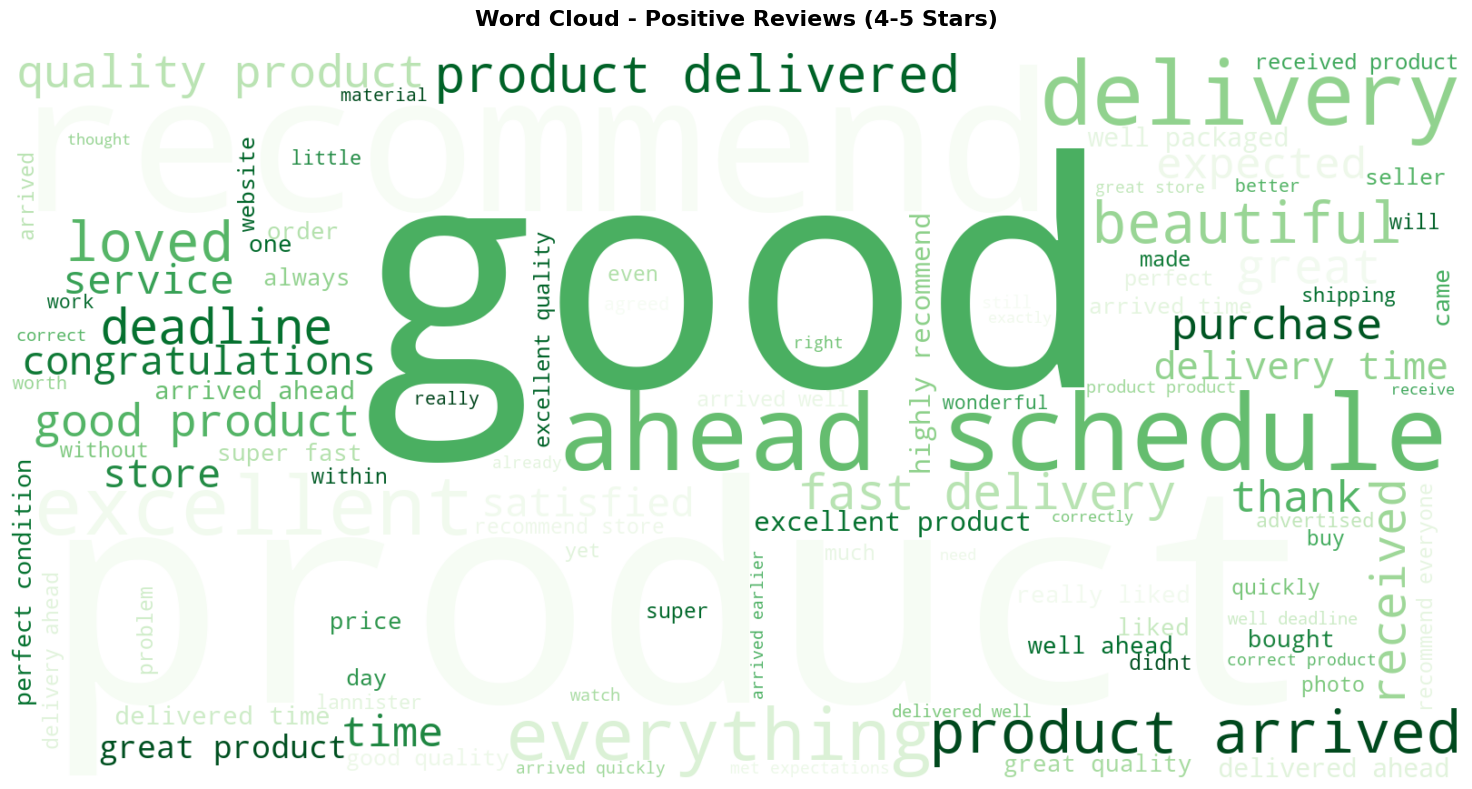

✓ Saved: wordcloud_positive.png


In [ ]:
from wordcloud import WordCloud

print('\nGenerating word clouds...')

positive_text = ' '.join(
    [' '.join(words) for words in reviews_en[reviews_en['review_category'] == 'positive']['cleaned_words']]
)

wordcloud_pos = WordCloud(
    width=1600, height=800,
    background_color='white',
    colormap='Greens',
    max_words=100
).generate(positive_text)

plt.figure(figsize=(16, 8))
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud - Positive Reviews (4-5 Stars)', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('wordcloud_positive.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: wordcloud_positive.png')

## 11. 워드클라우드 — 부정 리뷰

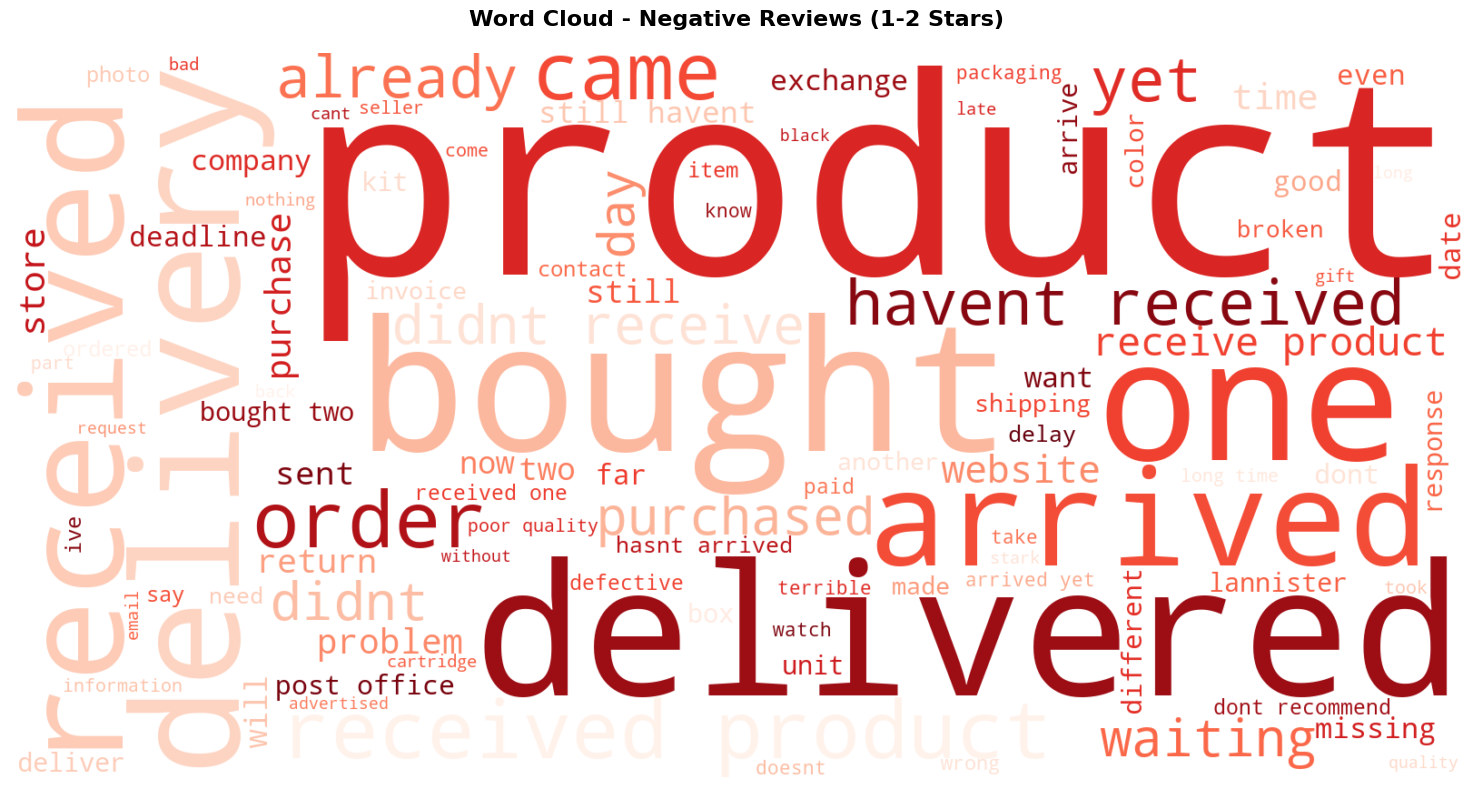

✓ Saved: wordcloud_negative.png


In [ ]:
negative_text = ' '.join(
    [' '.join(words) for words in reviews_en[reviews_en['review_category'] == 'negative']['cleaned_words']]
)

wordcloud_neg = WordCloud(
    width=1600, height=800,
    background_color='white',
    colormap='Reds',
    max_words=100
).generate(negative_text)

plt.figure(figsize=(16, 8))
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud - Negative Reviews (1-2 Stars)', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('wordcloud_negative.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: wordcloud_negative.png')

---
## 12. (보너스) VADER 감성 분석

VADER는 영어 전용 감성분석기라 번역된 영어 리뷰에 바로 적용 가능합니다.

In [ ]:
sia = SentimentIntensityAnalyzer()

# compound score: -1(부정) ~ +1(긍정)
reviews_en['sentiment'] = reviews_en['Review Text'].apply(
    lambda t: sia.polarity_scores(str(t))['compound']
)

# 라벨 부여
def label(score):
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    return 'neutral'

reviews_en['sentiment_label'] = reviews_en['sentiment'].apply(label)

# 평점 vs VADER 라벨 교차표
print('\n평점별 VADER 감성 라벨 분포(%):')
crosstab = pd.crosstab(reviews_en['Rating'], reviews_en['sentiment_label'],
                       normalize='index').round(3) * 100
print(crosstab)

# 평점별 평균 compound
print('\n평점별 평균 VADER compound:')
print(reviews_en.groupby('Rating')['sentiment'].agg(['mean', 'count']).round(3))

reviews_en.to_csv('reviews_with_sentiment.csv', index=False)
print('\n✓ Saved: reviews_with_sentiment.csv')


평점별 VADER 감성 라벨 분포(%):
sentiment_label  negative  neutral  positive
Rating                                      
1                    40.8     37.4      21.7
2                    41.6     33.5      24.8
3                    22.7     34.4      42.9
4                    11.3     23.1      65.6
5                     1.8     16.4      81.8

평점별 평균 VADER compound:
         mean  count
Rating              
1      -0.117    612
2      -0.058    161
3       0.107    273
4       0.314    485
5       0.505   1514

✓ Saved: reviews_with_sentiment.csv


/var/folders/3z/x60jqlxn6vx6dd5wzhzxq0100000gn/T/ipykernel_36086/263437624.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=reviews_en, x='Rating', y='sentiment', palette='RdYlGn')


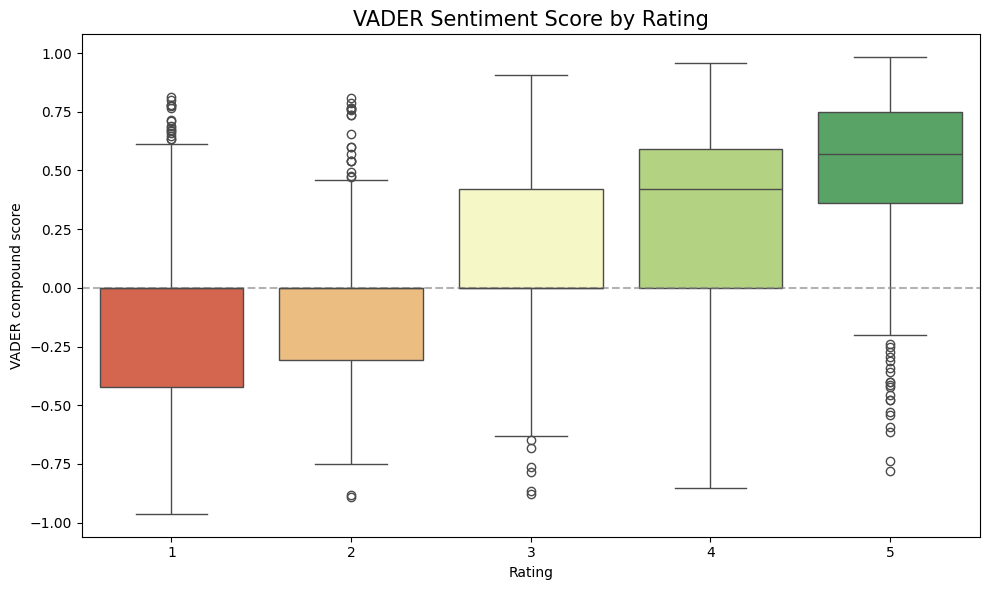

✓ Saved: sentiment_by_rating.png


In [ ]:
# 평점 vs 감성 시각화
plt.figure(figsize=(10, 6))
sns.boxplot(data=reviews_en, x='Rating', y='sentiment', palette='RdYlGn')
plt.title('VADER Sentiment Score by Rating', fontsize=15)
plt.axhline(0, color='gray', linestyle='--', alpha=0.6)
plt.ylabel('VADER compound score')
plt.tight_layout()
plt.savefig('sentiment_by_rating.png', dpi=200, bbox_inches='tight')
plt.show()
print('✓ Saved: sentiment_by_rating.png')

# 리뷰 스코어링 + 마스터 데이터셋 생성

# 이 노트북은 **`olist_review_text_mining.ipynb`(경로 B)** 의 후속 작업입니다.

## 목적
1. **모든 리뷰**(텍스트 없는 것 포함, 99,224건)에 감성 점수 + 라벨 부여
2. **평점 ↔ 텍스트 감성** 일치/불일치 라벨링 (`mismatch_type`)
3. orders / items / products / sellers / customers / payments 조인
4. 두 그레인의 **마스터 데이터셋** 생성:
4. 두 그레인의 **마스터 데이터셋** 생성:
   - `master_review_level.csv` — 리뷰 1건 = 1행 (다른 변수와 관계 분석용)
   - `master_review_item_level.csv` — 리뷰 × 상품 × 판매자 (카테고리/판매자 분석용)
5. 미스매치 케이스의 카테고리 / 판매자 분포 분석

## 1. 모든 리뷰에 감성 점수·라벨 부여

**사전 + 부정문 처리 방식**으로 직접 점수화 (번역 없이 포르투갈어 그대로). 
VADER 감성점수가 이미 있다면 그걸 사용해도 OK.

In [ ]:
import pandas as pd
import numpy as np
import re

reviews_raw = pd.read_csv('olist_order_reviews_dataset.csv')
reviews_raw['review_comment_message'] = reviews_raw['review_comment_message'].fillna('')

print(f'전체 리뷰: {len(reviews_raw):,}건')
print(f'  - 텍스트 있음: {(reviews_raw["review_comment_message"]!="").sum():,}건')
print(f'  - 텍스트 없음: {(reviews_raw["review_comment_message"]=="").sum():,}건')

전체 리뷰: 99,224건
  - 텍스트 있음: 40,977건
  - 텍스트 없음: 58,247건


In [ ]:
# 포르투갈어 감성 사전
positive_words = {
    'ótimo':2,'otimo':2,'ótima':2,'otima':2,'excelente':2,'excelentes':2,
    'perfeito':2,'perfeita':2,'maravilhoso':2,'maravilhosa':2,
    'amei':2,'adorei':2,'amo':2,'gostei':1,'gosto':1,
    'bom':1,'boa':1,'bons':1,'boas':1,'bem':1,
    'recomendo':2,'recomendado':1,'recomendada':1,
    'super':1,'top':1,'lindo':1,'linda':1,'lindas':1,'lindos':1,
    'rápido':1,'rapida':1,'rapido':1,'rápida':1,
    'satisfeito':1,'satisfeita':1,'satisfação':1,
    'parabéns':1,'parabens':1,'aprovado':1
}
negative_words = {
    'péssimo':-2,'pessimo':-2,'péssima':-2,'pessima':-2,
    'horrível':-2,'horrivel':-2,'terrível':-2,'terrivel':-2,
    'ruim':-2,'ruins':-2,'lixo':-2,'porcaria':-2,
    'defeito':-2,'defeituoso':-2,'defeituosa':-2,'quebrado':-2,'quebrada':-2,
    'errado':-1,'errada':-1,'falta':-1,'faltou':-1,'faltando':-1,
    'decepção':-2,'decepcionado':-2,'decepcionada':-2,'decepcionante':-2,
    'devolver':-1,'devolução':-1,'devolucao':-1,'reembolso':-1,
    'cancelar':-1,'cancelado':-1,
    'atrasado':-1,'atrasada':-1,'atraso':-1,'demorou':-1,'demora':-1,
    'pior':-1,'arrependi':-2,'fraco':-1,'fraca':-1,
    'roubo':-2,'fraude':-2
}
negators = {'não','nao','nem','nunca','jamais'}
neg_followers = {'recebi','recebido','chegou','chegei','veio','funciona','recomendo','gostei'}

def score_text(text):
    """감성 점수와 매칭 단어 수를 함께 반환"""
    if not text or pd.isna(text):
        return 0, 0
    t = re.sub(r'[^a-záàâãéèêíïóôõöúüç\s]', ' ', str(text).lower())
    words = t.split()
    score, matches = 0, 0
    for i, w in enumerate(words):
        prev_neg = (i > 0 and words[i-1] in negators)
        if w in positive_words:
            score += -positive_words[w] if prev_neg else positive_words[w]
            matches += 1
        elif w in negative_words:
            score += negative_words[w]
            matches += 1
        # 'não recebi', 'não chegou' 같은 표현 추가 점수
        if w in {'não','nao'} and i+1 < len(words) and words[i+1] in neg_followers:
            score -= 2
            matches += 1
    return score, matches

scores = reviews_raw['review_comment_message'].apply(score_text)
reviews_raw['sent_score']   = scores.apply(lambda x: x[0])
reviews_raw['sent_matches'] = scores.apply(lambda x: x[1])
reviews_raw['text_length']  = reviews_raw['review_comment_message'].str.len()
reviews_raw['has_text']     = reviews_raw['text_length'] > 0

reviews_raw[['review_id','review_score','sent_score','sent_matches','text_length']].head()

,review_id,review_score,sent_score,sent_matches,text_length
0,7bc2406110b926393aa56f80a40eba40,4,0,0,0
1,80e641a11e56f04c1ad469d5645fdfde,5,0,0,0
2,228ce5500dc1d8e020d8d1322874b6f0,5,0,0,0
3,e64fb393e7b32834bb789ff8bb30750e,5,1,1,37
4,f7c4243c7fe1938f181bec41a392bdeb,5,4,3,100


In [ ]:
# 감성 라벨 (positive / neutral / negative / no_text)
def label(s, has):
    if not has: return 'no_text'
    if s >= 1: return 'positive'
    elif s <= -1: return 'negative'
    return 'neutral'

reviews_raw['sent_label'] = reviews_raw.apply(
    lambda r: label(r['sent_score'], r['has_text']), axis=1)

# 평점 카테고리 (high=4-5, mid=3, low=1-2)
def rating_cat(r):
    if r >= 4: return 'high'
    elif r <= 2: return 'low'
    return 'mid'
reviews_raw['rating_cat'] = reviews_raw['review_score'].apply(rating_cat)

# ⭐ 미스매치 타입 — 여기가 핵심 라벨
def mismatch_type(row):
    if not row['has_text']: return 'no_text'
    rc, sl = row['rating_cat'], row['sent_label']
    if rc == 'high' and sl == 'negative': return 'high_rating_negative_text'   # ⚠️ 4-5점인데 부정 텍스트
    if rc == 'low'  and sl == 'positive': return 'low_rating_positive_text'    # ⚠️ 1-2점인데 긍정 텍스트
    if rc == 'high' and sl == 'positive': return 'aligned_positive'
    if rc == 'low'  and sl == 'negative': return 'aligned_negative'
    return 'mid_or_neutral'

reviews_raw['mismatch_type'] = reviews_raw.apply(mismatch_type, axis=1)

print('✅ 모든 리뷰 점수화/라벨링 완료\n')
print('미스매치 타입 분포:')
print(reviews_raw['mismatch_type'].value_counts())

✅ 모든 리뷰 점수화/라벨링 완료

미스매치 타입 분포:
mismatch_type
no_text                      58247
aligned_positive             18640
mid_or_neutral               15773
aligned_negative              5255
high_rating_negative_text      729
low_rating_positive_text       580
Name: count, dtype: int64


---
## 2. 다른 데이터셋 로드 + 조인

orders / order_items / products / sellers / customers / payments 모두 결합.

In [ ]:
orders     = pd.read_csv('olist_orders_dataset.csv')
items      = pd.read_csv('olist_order_items_dataset.csv')
products   = pd.read_csv('olist_products_dataset.csv')
customers  = pd.read_csv('olist_customers_dataset.csv')
sellers    = pd.read_csv('olist_sellers_dataset.csv')
payments   = pd.read_csv('olist_order_payments_dataset.csv')
cat_trans  = pd.read_csv('product_category_name_translation.csv')

# 카테고리 영문명 부착
products = products.merge(cat_trans, on='product_category_name', how='left')

# 결제: 한 주문에 여러 결제 가능 → 합산
pay_agg = payments.groupby('order_id').agg(
    payment_value=('payment_value','sum'),
    payment_type=('payment_type', lambda x: x.mode().iat[0] if len(x.mode())>0 else 'unknown'),
    payment_installments=('payment_installments','max')
).reset_index()

# 주문 + 고객 + 결제
order_full = (orders
    .merge(customers, on='customer_id', how='left')
    .merge(pay_agg,   on='order_id',    how='left'))

# 배송 일자 → datetime
for c in ['order_purchase_timestamp','order_delivered_customer_date','order_estimated_delivery_date']:
    order_full[c] = pd.to_datetime(order_full[c], errors='coerce')

order_full['delivery_days']       = (order_full['order_delivered_customer_date']
                                     - order_full['order_purchase_timestamp']).dt.days
order_full['delivery_delay_days'] = (order_full['order_delivered_customer_date']
                                     - order_full['order_estimated_delivery_date']).dt.days
order_full['is_late'] = order_full['delivery_delay_days'] > 0

# 아이템 + 상품 + 판매자
item_full = (items
    .merge(products[['product_id','product_category_name','product_category_name_english',
                     'product_weight_g','product_photos_qty']], on='product_id', how='left')
    .merge(sellers, on='seller_id', how='left'))

print(f'order_full: {len(order_full):,} rows')
print(f'item_full:  {len(item_full):,} rows')

order_full: 99,441 rows
item_full:  112,650 rows
